<a href="https://colab.research.google.com/github/Geralf21/Analisis_Patrocinios_Clubes_Brasileros/blob/main/notebooks/TP_Pregunta_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###¿Qué clubes lograron capitalizar en mayor medida el boom de las casas de apuestas y cómo aumentó la brecha de ingresos comerciales entre el club con mayor patrocionio y el de menor patrocinio de la serie A?

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

url = "https://raw.githubusercontent.com/Geralf21/Analisis_Patrocinios_Clubes_Brasileros/refs/heads/main/BaseDatos/patrocinios_brsileirao.csv"
df_panel = pd.read_csv(url)

df_panel.head()

,club,año,sponsor_master,monto_brl,rubro,es_bet,hinchas_m
0,Palmeiras,2023,Crefisa,81.0,Finanzas,0,15.0
1,Flamengo,2023,BRB,44.0,Banco,0,42.0
2,Botafogo,2023,Parimatch,27.5,Apuestas,1,3.5
3,Cruzeiro,2023,Betfair,25.0,Apuestas,1,6.5
4,São Paulo,2023,Sportsbet.io,24.0,Apuestas,1,16.0


Creamos un gráfico para 2023 y otro para 2024 que muestren como se distribuyeron los ingresos por patrocinio entre los clubes en cada año. En color verde se representa a los clubes cuyo patrocinador principal es una casa de apuestas y en azul a los patrocinados por rubros tradicionales.

En el gráfico se puede ver claramente como crecieron los sponsors de casas de apuestas del 2023 al 2024 y cómo algunos equipos optaron por adoptar un patrocinador de este rubro.

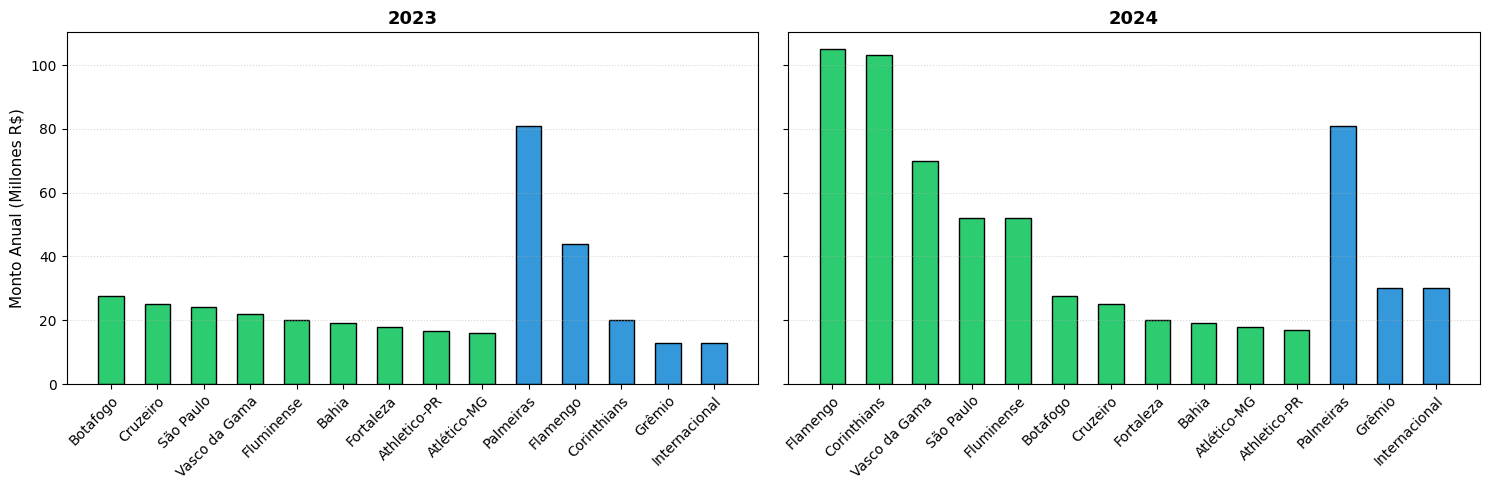

In [11]:
df_23 = (df_panel[df_panel["año"] == 2023].sort_values(by=["es_bet", "monto_brl"], ascending=[False, False]).reset_index(drop=True))

df_24 = (df_panel[df_panel["año"] == 2024].sort_values(by=["es_bet", "monto_brl"], ascending=[False, False]).reset_index(drop=True))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

ax1.bar(df_23["club"], df_23["monto_brl"], color=np.where(df_23["es_bet"] == 1, "#2ecc71", "#3498db"), edgecolor="black", width=0.55)
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"); ax1.set_title("2023", fontweight="bold", fontsize=13); ax1.set_ylabel("Monto Anual (Millones R$)", fontsize=11); ax1.grid(axis="y", linestyle=":", alpha=0.5)

ax2.bar(df_24["club"], df_24["monto_brl"], color=np.where(df_24["es_bet"] == 1, "#2ecc71", "#3498db"), edgecolor="black", width=0.55)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"); ax2.set_title("2024", fontweight="bold", fontsize=13); ax2.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout(); plt.show()

Calculamos cúanto dinero total se invirtió en sponsors de apuestas y en sponsors de rubros tradicionales tanto en 2023 como en 2024. Luego calculamos cúanto varió porcentualmente el total de apuestas y el de rubro tradicional.

Lo que se observa es que el total destinado a sponsors de apuestas creció un 170.3% y el total destinado a sponsors de rubros tradicionales decreció un 17.5%.

In [4]:
# Totales 2023
total_bets_23 = df_panel[df_panel["año"] == 2023].groupby("es_bet")["monto_brl"].sum()[1]
total_nobets_23 = df_panel[df_panel["año"] == 2023].groupby("es_bet")["monto_brl"].sum()[0]

# Totales 2024
total_bets_24 = df_panel[df_panel["año"] == 2024].groupby("es_bet")["monto_brl"].sum()[1]
total_nobets_24 = df_panel[df_panel["año"] == 2024].groupby("es_bet")["monto_brl"].sum()[0]

# Variaciones porcentuales
var_bets = ((total_bets_24 - total_bets_23) / total_bets_23) * 100
var_nobets = ((total_nobets_24 - total_nobets_23) / total_nobets_23) * 100

print(f"Total destinado a sponsors de apuestas: 2023: {total_bets_23:.1f} M | 2024: {total_bets_24:.1f} M | Crecimiento: {var_bets:+.2f}%")
print(f"Total destinado a sponsors tradicionales: 2023: {total_nobets_23:.1f} M | 2024: {total_nobets_24:.1f} M | Crecimiento: {var_nobets:+.2f}%")

Total destinado a sponsors de apuestas: 2023: 188.1 M | 2024: 508.5 M | Crecimiento: +170.33%
Total destinado a sponsors tradicionales: 2023: 171.0 M | 2024: 141.0 M | Crecimiento: -17.54%


Calculamos como aumentó la brecha hacia el 2024 entre el club de mayor ingresos por sponsor y el club de menor.

Lo que se observa es que la brecha aumentó un 29.41%.

In [9]:
# Brechas absolutas
brecha_23 = df_23["monto_brl"].max() - df_23["monto_brl"].min()
brecha_24 = df_24["monto_brl"].max() - df_24["monto_brl"].min()

# Variación porcentual de la brecha
var_brecha = ((brecha_24 - brecha_23) / brecha_23) * 100

print(f"Brecha 2023: {brecha_23:.1f} M | Brecha 2024: {brecha_24:.1f} M | Aumento: {var_brecha:.2f}%")

Brecha 2023: 68.0 M | Brecha 2024: 88.0 M | Aumento: 29.41%


Calculamos ahora cual es el promedio de ingresos por sponsors de apuestas en 2023 y en 2024 y cómo aumento de un año para el otro.

Lo que se observa es que el promedio aumentó un 121.18%, un aumento significativamente menor al aumento del total invertido en sponsors de apuestas. Esto muestra que el nuevo volumen de dinero no se distribuyó de manera uniforme entre los equipos. ¿Bajo qué criterio económico se distribuyó el dinero entre clubes?

In [7]:
promedio_23_bet = df_23[df_23["es_bet"] == 1]["monto_brl"].mean()
promedio_24_bet = df_24[df_24["es_bet"] == 1]["monto_brl"].mean()
var_bet = ((promedio_24_bet - promedio_23_bet) / promedio_23_bet) * 100

print(f"Promedio de ingresos por sponsors de apuestas entre clubes 2023 = {promedio_23_bet:.2f} M | 2024 = {promedio_24_bet:.2f} M | Aumento = {var_bet:.2f}%")

Promedio de ingresos por sponsors de apuestas entre clubes 2023 = 20.90 M | 2024 = 46.23 M | Aumento = 121.18%


Hacemos un gráfico que muestre la distribución de ingresos y de cantidad de hinchas por club.

Lo que se observa es que hay una fuerte correlación positiva entre los ingresos y la cantidad de hinchas.

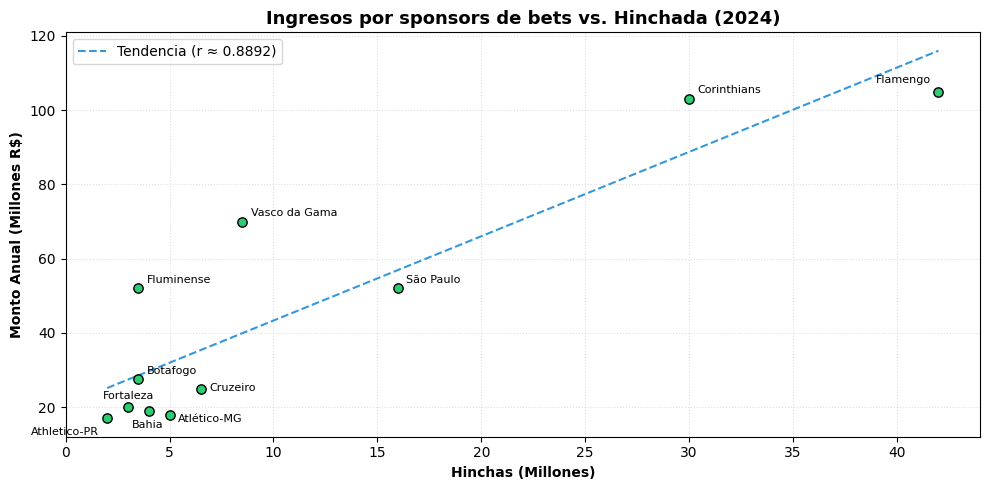

In [26]:
df_b24 = df_24[df_24["es_bet"] == 1].sort_values(by="monto_brl", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))

# 1. Puntos más chicos: s=45 en vez de 80
ax.scatter(df_b24["hinchas_m"], df_b24["monto_brl"], color="#2ecc71", edgecolor="black", s=45, zorder=3)

# 2. Recta de regresión azul: color="#3498db"
m, b = np.polyfit(df_b24["hinchas_m"], df_b24["monto_brl"], 1)
x_line = np.linspace(df_b24["hinchas_m"].min(), df_b24["hinchas_m"].max(), 100)
ax.plot(x_line, m * x_line + b, color="#3498db", linestyle="--", label="Tendencia (r ≈ 0.8892)")

# 3. Offsets manuales para que los nombres de clubes de abajo no se superpongan
offsets = {
    "Athletico-PR": (-55, -12),
    "Fortaleza": (-18, 6),
    "Bahia": (-12, -12),
    "Atlético-MG": (6, -5),
    "Cruzeiro": (6, -2),
    "Botafogo": (6, 4),
    "Flamengo": (-45, 6)
}

for _, row in df_b24.iterrows():
    dx, dy = offsets.get(row["club"], (6, 4))
    ax.annotate(row["club"], (row["hinchas_m"], row["monto_brl"]),
                textcoords="offset points", xytext=(dx, dy), fontsize=8)

ax.set_xlabel("Hinchas (Millones)", fontweight="bold")
ax.set_ylabel("Monto Anual (Millones R$)", fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.4)
ax.legend()

plt.title("Ingresos por sponsors de bets vs. Hinchada (2024)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

Calculamos el coeficiente de Pearson para cuantificar esta correlación.

Un valor de 0,8892 es notablemente cercano a 1, lo que confirma la fuerte correlación lineal observada en el gráfico anterior. Esto sugiere que las casas de apuestas concentraron estratégicamente su capital entre los clubes con mayor alcance. A su vez, la capacidad financiera para absorber los contratos de los equipos más grandes muestra el gran salto económico que experimentó el sector.

In [ ]:
# Filtramos solo los clubes con apuestas en 2024
bets_24 = df_panel[(df_panel["año"] == 2024) & (df_panel["es_bet"] == 1)]

# Coeficiente de Pearson directo con Pandas
r = bets_24["monto_brl"].corr(bets_24["hinchas_m"])
print(f"Coeficiente de Pearson (r): {r:.4f}")

Coeficiente de Pearson (r): 0.8892


Para justificar despues: A los fines de este análisis, puede tomarse como variable representativa de los ingresos comerciales al valor del patrocinador máster (los ingresos de la base de datos usada corresponden solamente al patrocinador principal). En la industria del fútbol brasileño, este activo concentra la mayor parte del valor del uniforme y funciona como el principal indicador de la cotización comercial de cada institución, permitiendo una comparación estandarizada y homogénea entre los clubes.